## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Adeline Kwakye

**Date:** 10/19/2026

[6, 30, 4, 2, 150, 28, 21, 4, 4, 389, 31, 1, 1, 85, 115, 78, 2, 22, 97, 95, 6, 11, 1, 22, 324, 41, 178, 373, 16, 82, 15, 1365, 58, 18, 3, 21, 1, 2, 501, 110, 8, 17, 7, 798, 22, 8, 125, 8, 9, 116, 93, 14, 14, 680, 14, 234, 229, 54, 1, 1, 10, 5, 3, 21, 34, 105, 67, 5, 229, 1, 166, 121, 176, 147, 63, 117, 95, 19, 90, 39, 24, 138, 8, 12, 79, 305, 12, 869, 1, 117, 11, 44, 32, 1052, 52, 3, 13, 609, 7, 17, 3, 166, 1, 1, 110, 2, 1, 2, 33, 172, 27, 2, 2, 3, 124, 17, 6, 2, 45, 2, 27, 5, 21, 32, 352, 651, 24, 221, 142, 85, 127, 138, 172, 14, 188, 79, 43, 7, 6, 68, 175, 98, 397, 178, 47, 45, 43, 403, 316, 8, 421, 1, 164, 1, 1022, 31, 239, 161, 305, 81, 251, 625, 1, 1202, 1, 1, 1, 41, 187, 83, 90, 71, 265, 1, 40, 109, 82, 8, 17, 523, 208, 10, 10, 92, 129, 93, 8, 239, 4, 10, 1, 55, 1, 7, 205, 27, 25, 28, 5, 6, 125, 160, 587, 2, 11, 383, 3, 312, 553, 1, 114, 24, 50, 14, 4, 52, 61, 6, 134, 287, 4, 89, 1, 10, 20, 4, 40, 18, 26, 1, 1, 1, 5, 1, 1, 8, 6, 3, 7, 12, 550, 39, 138, 26, 806, 923, 174, 191, 10,

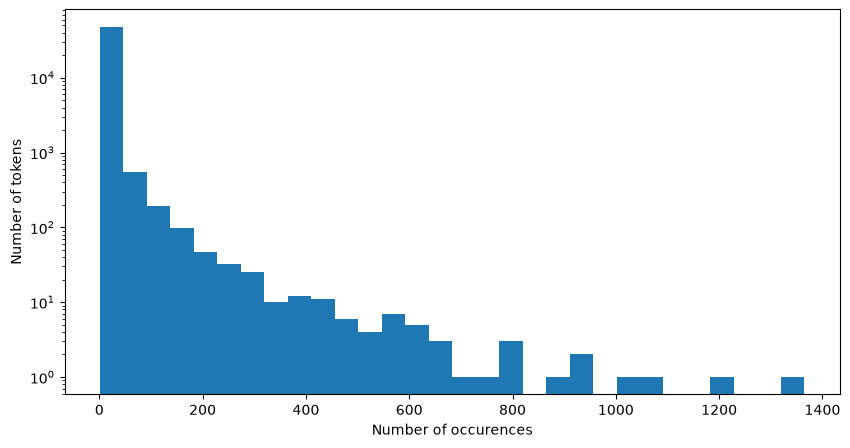

split data 80/20

Training test r-squared:  0.7678
Test r-squared:  0.6571

Top 10 token values 
aging                0.9965
helvetica,           0.8922
localized            0.7879
background-image:    0.7801
thermal              0.6710
12px;                0.6293
rcs                  0.5535
exercise!            0.5422
burning              0.5150
#000000;             0.5029
dtype: float64

tokens that indicate scams vs safe
aging                0.9965
helvetica,           0.8922
localized            0.7879
background-image:   -0.7801
thermal              0.6710
12px;                0.6293
rcs                  0.5535
exercise!            0.5422
burning             -0.5150
#000000;             0.5029
dtype: float64


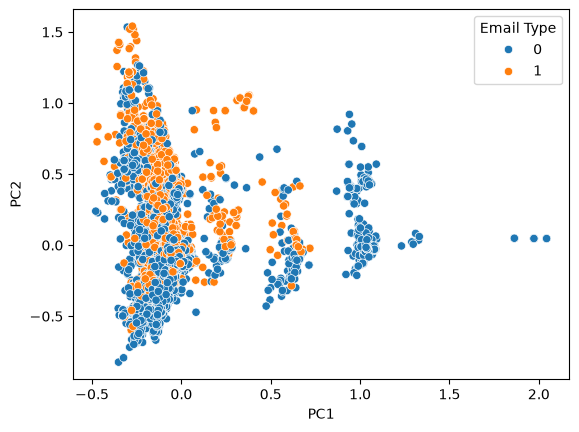

(14907, 2711)

Training pca shape:  (14907, 2610)

Test pca shape:  (3727, 2610)
PCA Regression Training test r-squared:  0.7669
PCA Regression Test r-squared:  0.6614


In [2]:
# Your Phase 1 solution to the problem goes here.
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA


with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

# listing out how often each token appears
token_values = list(token_count.values())
print(token_values)
# plot the distribution
plt.figure(figsize=(10,5))
plt.yscale('log')
plt.hist(token_values, bins=30)
plt.xlabel("Number of occurences")
plt.ylabel("Number of tokens")
plt.show()

# q2
df = pd.read_parquet('data/Phishing_clean.parquet')
# split data 80/20
print("split data 80/20\n")
X = df.drop(columns = ["Email Type"]) # features all columns except email type
y = df["Email Type"] # target email type

(X_train, X_valid, y_train, y_valid,) = train_test_split(X, y, test_size = 0.20, random_state = 65 )

# run linear regression on y
model = LinearRegression()
model.fit(X_train,y_train)
# evaluates r^2 on training and test sets
r2_train = model.score(X_train,y_train)
r2_valid = model.score(X_valid, y_valid)

print("Training test r-squared: ", round(r2_train, 4))
print("Test r-squared: ", round(r2_valid,4))

# find most influential tokens
coef_series = pd.Series(model.coef_, index=X_train.columns)
# top 10 tokens based on absolute value
top_tokens_absolute = coef_series.abs().sort_values(ascending=False).head(10)
print("\nTop 10 token values ")
print(top_tokens_absolute.round(4))
# to determine which words are scams vs safe
print("\ntokens that indicate scams vs safe")
print(coef_series.loc[top_tokens_absolute.index].round(4))


# q3

# fit pca with 2 dimensions
pca_2 = PCA(n_components = 2).fit(X)
X_pca_sklearn = pca_2.transform(X)

#put in df to help make scatter plot

pca_df = pd.DataFrame(X_pca_sklearn, columns =["PC1", "PC2"])
pca_df['Email Type'] = y.values
# scatter plot
sns.scatterplot(
    data = pca_df,
    x= "PC1",
    y="PC2",
    hue = "Email Type"
)
plt.show()


# q4
print(X_train.shape)
pca_regression = PCA(n_components=2610)
X_train_pca = pca_regression.fit_transform(X_train)
X_valid_pca = pca_regression.transform(X_valid)

print("\nTraining pca shape: ", X_train_pca.shape)
print("\nTest pca shape: ", X_valid_pca.shape)
# run linear regression
pca_regression_model = LinearRegression()
pca_regression_model.fit(X_train_pca,y_train)

pca_regression_r2_train = pca_regression_model.score(X_train_pca, y_train)
pca_regression_r2_valid = pca_regression_model.score(X_valid_pca, y_valid)

print("PCA Regression Training test r-squared: ", round(pca_regression_r2_train, 4))
print("PCA Regression Test r-squared: ", round(pca_regression_r2_valid,4))

Q1.
The histogram appears to be right-skewed. Prior to scaling the plot, almost all the data appeared to be compressed into the very first bar next to zero. After doing a logarithmic scale of the y-axis, the distribution shows that the number of unique tokens drops as occurences increases. The majority of unique tokens appear only a few times across the entire dataset and only a small amount of tokens occur repeatedly.

Q2.
The linear regression model had an R-squared of 0.7678 on the training data and 0.6571 on the test data. The higher training score suggests that the model fits the training data better as opposed to the unseen test data. The tokens that had the largest absolute coefficients were aging, helvetica, and localized. Aging had the largest coefficent in absolute value of 0.9965, meaning that it had the strongest influence on predictions. Other tokens also had large absolute value coefficients like helvitica with 0.8922, localized with 0.7879 and background-image with 0.7801. The absolute values show the magnitude of each coefficient. 

Q3.
The scatter plot shows a huge overlap between phising and legitimate emails, especially in the first main cluster. This shows that the first two principal components don't distinctly distinguish between the two kinds of emails. For The areas with higher PC1 values contain mostly legitimate emails, which lets us know that some pattersn in the data are more common in legitmate emails as opposed to phishing emails. 

Q4.
The principal component regression model had a training R^2 of 0.7669 and a test R^2 of 0.6614. Compared to the original linear regression model, which had a training R^2 of 0.7678 and a test R^2 of 0.6571, the performance was fairly similar. The principal comonent regression had a slightly lower training R^2, but a slightly higher test R^2, which suggests that it performed better on the test set.

Q5. 
An advantage of using principal components would be that they reduce the number of features in the dataset while at the same time retaining much of the variation. This allows for the regression to be more computationally manageable and reduce issues caused by the numerous features. In this case, the principal component responded fairly similar to the original linear regression, with a slightly higher test R^2.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 32c3050445b4ec18f4cf4344cd47b3eb65804c41
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. hi claude! do you think you can look over my homework code and answers and give me tips and improvements on how to fix it? I'll attach my homeowork and code. 



### *AI-proposed changes



1. Two ways to sharpen it:

“Right-skewed” is fine, but “heavy-tailed” is the more precise term, since a few tokens dominate while most are rare. You could mention that this resembles Zipf’s law, where frequency falls off roughly as 1/rank.
A log-log plot or a log-scaled x-axis shows this shape better than 30 linear bins:
python
plt.hist(token_values, bins=np.logspace(0, np.log10(max(token_values)), 40))
plt.xscale('log'); plt.yscale('log')

You also mention how the plot looked “prior to scaling,” but your code only shows the log version. That’s fine, but make sure the comparison is reflected in your submission.


2. Overfitting: Name it. A train R² of 0.77 vs. a test R² of 0.66 is an ~11-point gap, which is classic overfitting with 2,700+ features.
Direction is missing: You printed the signed coefficients but never reported them. The question is about which words influence predictions, so say which push toward scam (positive) and which toward legitimate (negative). Your last sentence (“The absolute values show the magnitude”) is filler, so replace it with this.
Caveat: Large coefficients on rare tokens (some appear in only 15 emails) can be noisy, especially with correlated features, so a big coefficient isn’t necessarily strong evidence.
Code: top_tokens_absolute stores absolute values, so the first print can’t show direction. This version gives you signed values in order of magnitude:
python
top10 = coef_series.reindex(coef_series.abs().sort_values(ascending=False).index).head(10)
Typos: “Training test r-squared” should be “Training r-squared,” and “helvitica” should be “helvetica.”


3. This is where I’d change the most. Your numbers (0.6614 vs. 0.6571) show the models are essentially identical, so saying PCR “performed 
better on the test set” overclaims. A 0.004 difference on a single random split is noise. I’d say they perform about the same, and explain why: if X has ~2,710 features and you kept 2,610 components, you’ve kept almost all the information. Using all components gives exactly the same fit as ordinary regression (PCA is just a rotation of the same space), so near-identical results are expected.

If you want to show more, plot test R² against the number of components:

python
for k in [10, 50, 100, 500, 1000, 2610]:
    ...

    
4. Your answer is correct but generic, and the last sentence is about results rather than the advantage. Stronger points to include:

PCs are uncorrelated, which removes multicollinearity among the word features and stabilizes coefficients.
Keeping fewer components reduces variance and overfitting, and speeds up computation. You can choose how many to keep with cross-validation.
The tradeoff is interpretability, since components are mixtures of words and no longer map to individual tokens.
Be honest that with 2,610 components you don’t see much benefit here. The advantage shows up when you keep far fewer.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | modify | I chose to modify this because I think it could be beneficial to how the before scaling and after scaling plot since I make it a point to mention it in my explanation. However I do think that maybe Claude was slightly knit picky with some of the terms and they might not be necessary for this particular question. |
| 2 | Accept| I chose to accept this because Claude pointed out pretty concrete points that i missed or overlooked. I think I did have some confusion and uncertainty with how to use some of the values that I found so I felt like this point helped clarify some concerns and questions i had.  |
| 3 | modify | I chose to modify this because while I don't feel like adding more plots to test r^2 i do think a good point was mentioned in tweaking my sentence to strengthen up my claim. The difference is a 0.004 which isn't extremly significant and my answer should reflect that as well. |
| 4 | modify | I chose to modify this because while I won't add every additional point made, I do think that Claude brought up some pretty important and topics that should be included in my final answer that I overlooked. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

[6, 30, 4, 2, 150, 28, 21, 4, 4, 389, 31, 1, 1, 85, 115, 78, 2, 22, 97, 95, 6, 11, 1, 22, 324, 41, 178, 373, 16, 82, 15, 1365, 58, 18, 3, 21, 1, 2, 501, 110, 8, 17, 7, 798, 22, 8, 125, 8, 9, 116, 93, 14, 14, 680, 14, 234, 229, 54, 1, 1, 10, 5, 3, 21, 34, 105, 67, 5, 229, 1, 166, 121, 176, 147, 63, 117, 95, 19, 90, 39, 24, 138, 8, 12, 79, 305, 12, 869, 1, 117, 11, 44, 32, 1052, 52, 3, 13, 609, 7, 17, 3, 166, 1, 1, 110, 2, 1, 2, 33, 172, 27, 2, 2, 3, 124, 17, 6, 2, 45, 2, 27, 5, 21, 32, 352, 651, 24, 221, 142, 85, 127, 138, 172, 14, 188, 79, 43, 7, 6, 68, 175, 98, 397, 178, 47, 45, 43, 403, 316, 8, 421, 1, 164, 1, 1022, 31, 239, 161, 305, 81, 251, 625, 1, 1202, 1, 1, 1, 41, 187, 83, 90, 71, 265, 1, 40, 109, 82, 8, 17, 523, 208, 10, 10, 92, 129, 93, 8, 239, 4, 10, 1, 55, 1, 7, 205, 27, 25, 28, 5, 6, 125, 160, 587, 2, 11, 383, 3, 312, 553, 1, 114, 24, 50, 14, 4, 52, 61, 6, 134, 287, 4, 89, 1, 10, 20, 4, 40, 18, 26, 1, 1, 1, 5, 1, 1, 8, 6, 3, 7, 12, 550, 39, 138, 26, 806, 923, 174, 191, 10,

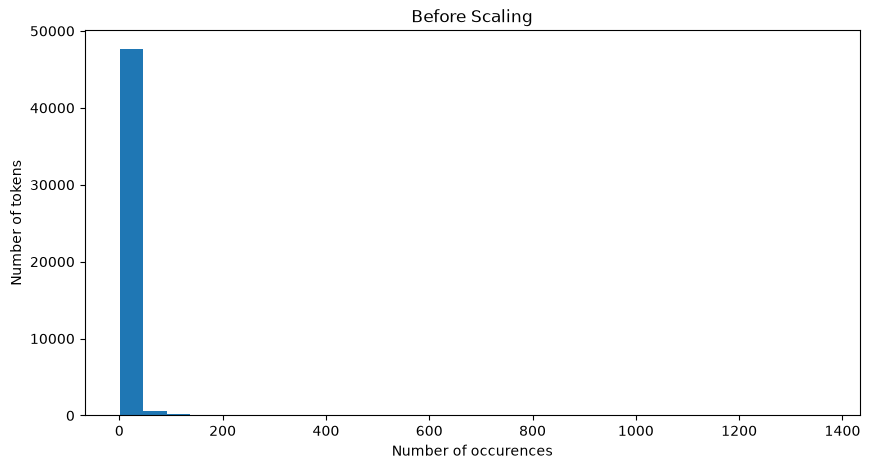

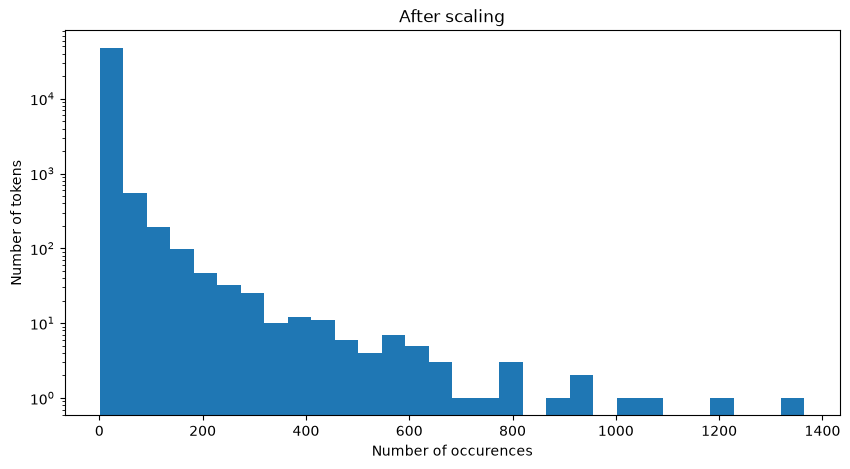

split data 80/20

Training test r-squared:  0.7678
Test r-squared:  0.6571

 Top 10 tokens based on absolute coefficent magnitude:
aging                0.9965
helvetica,           0.8922
localized            0.7879
background-image:   -0.7801
thermal              0.6710
12px;                0.6293
rcs                  0.5535
exercise!            0.5422
burning             -0.5150
#000000;             0.5029
dtype: float64


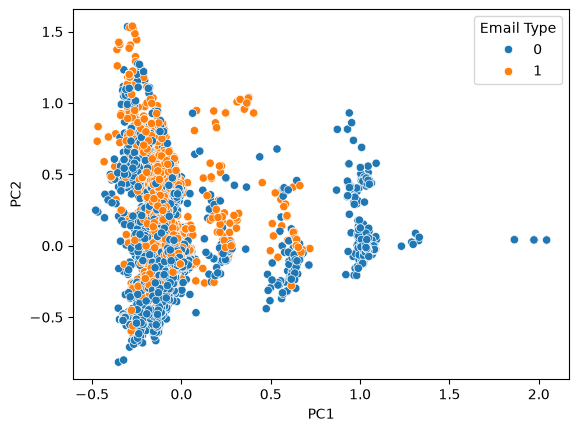

(14907, 2711)

Training pca shape:  (14907, 2610)

Test pca shape:  (3727, 2610)
PCA Regression Training test r-squared:  0.7669
PCA Regression Test r-squared:  0.6614


In [3]:
# Your Phase 2 solution to the problem goes here.
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA


with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

# listing out how often each token appears
token_values = list(token_count.values())
print(token_values)
# plot the distribution before scaling
plt.figure(figsize=(10,5))
plt.hist(token_values, bins=30)
plt.title("Before Scaling")
plt.xlabel("Number of occurences")
plt.ylabel("Number of tokens")
plt.show()
#after scaling 
plt.figure(figsize=(10,5))
plt.yscale('log')
plt.hist(token_values, bins=30)
plt.title("After scaling")
plt.xlabel("Number of occurences")
plt.ylabel("Number of tokens")
plt.show()

# q2
df = pd.read_parquet('data/Phishing_clean.parquet')
# split data 80/20
print("split data 80/20\n")
X = df.drop(columns = ["Email Type"]) # features all columns except email type
y = df["Email Type"] # target email type

(X_train, X_valid, y_train, y_valid,) = train_test_split(X, y, test_size = 0.20, random_state = 65 )

# run linear regression on y
model = LinearRegression()
model.fit(X_train,y_train)
# evaluates r^2 on training and test sets
r2_train = model.score(X_train,y_train)
r2_valid = model.score(X_valid, y_valid)

print("Training test r-squared: ", round(r2_train, 4))
print("Test r-squared: ", round(r2_valid,4))

# find most influential tokens
coef_series = pd.Series(model.coef_, index=X_train.columns)
# top 10 tokens based on absolute value
#top_tokens_absolute = coef_series.abs().sort_values(ascending=False).head(10)
#print("\nTop 10 token values ")
#print(top_tokens_absolute.round(4))
# to determine which words are scams vs safe
#print("\ntokens that indicate scams vs safe")
#print(coef_series.loc[top_tokens_absolute.index].round(4))

top_10 = coef_series.loc[
    coef_series.abs().sort_values(ascending=False).head(10).index
] # ensures that the actual signed coefficients in order of absolute magnitude

print("\n Top 10 tokens based on absolute coefficent magnitude:")
print(top_10.round(4))


# q3

# fit pca with 2 dimensions
pca_2 = PCA(n_components = 2).fit(X)
X_pca_sklearn = pca_2.transform(X)

#put in df to help make scatter plot

pca_df = pd.DataFrame(X_pca_sklearn, columns =["PC1", "PC2"])
pca_df['Email Type'] = y.values
# scatter plot
sns.scatterplot(
    data = pca_df,
    x= "PC1",
    y="PC2",
    hue = "Email Type"
)
plt.show()


# q4
print(X_train.shape)
pca_regression = PCA(n_components=2610)
X_train_pca = pca_regression.fit_transform(X_train)
X_valid_pca = pca_regression.transform(X_valid)

print("\nTraining pca shape: ", X_train_pca.shape)
print("\nTest pca shape: ", X_valid_pca.shape)
# run linear regression
pca_regression_model = LinearRegression()
pca_regression_model.fit(X_train_pca,y_train)

pca_regression_r2_train = pca_regression_model.score(X_train_pca, y_train)
pca_regression_r2_valid = pca_regression_model.score(X_valid_pca, y_valid)

print("PCA Regression Training test r-squared: ", round(pca_regression_r2_train, 4))
print("PCA Regression Test r-squared: ", round(pca_regression_r2_valid,4))

Q1.
The histogram appears to be right-skewed. Prior to scaling the plot, almost all the data appeared to be compressed into the very first bar next to zero, making it hard to see the distribution. After doing a logarithmic scale of the y-axis, we can easily see that the distribution shows that the number of unique tokens drops as occurences increases. The majority of unique tokens appear only a few times across the entire dataset and only a small amount of tokens occur repeatedly.

Q2.
The linear regression model had an R-squared of 0.7678 on the training data and 0.6571 on the test data. The 11 point gap suggests that the model is overfitting. This means that it fits patterns in the training data that don't entirely generalize to unseen emails. The tokens that had the largest absolute coefficients were aging, helvetica, and localized. Aging had the largest coefficent in absolute value of 0.9965, meaning that it had the strongest influence on predictions. A positive coefficient is associated with prediciting Email Type = 1, while a negative coefficient is associated with prediciting Email Type = 0. Other tokens also had large absolute value coefficients like helvetica with 0.8922, localized with 0.7879 and background-image with -0.7801. The absolute values show the magnitude. 

Q3.
The scatter plot shows a huge overlap between phising and legitimate emails, especially in the first main cluster. This shows that the first two principal components don't distinctly distinguish between the two kinds of emails. For the areas with higher PC1 values contain mostly legitimate emails, which lets us know that some patterns in the data are more common in legitmate emails as opposed to phishing emails. 

Q4.
The principal component regression model had a training R^2 of 0.7669 and a test R^2 of 0.6614. Compared to the original linear regression model, which had a training R^2 of 0.7678 and a test R^2 of 0.6571, the performance was fairly similar. The difference between the two was about 0.004 which isn't a significant difference and could be attributed to noise. Out of the 2,710 features, we kept 2,610 which is almost all the information. Despite using fewering features we still had roughly the same fit as the ordinary regression, which was expected.

Q5. 
An advantage of using principal components would be that they reduce the number of features in the dataset while at the same time retaining much of the variation. This allows for the regression to be more computationally manageable and reduce issues caused by the numerous features. With keeping only the top components, we reduce the risk of overfitting since there's less parameters to fit. Along with that, with having components that aren't correlated with each other, it makes the coefficients more stable and help remove multicollinearity. In this case, the benefit of removing features was fairly small, since we kept rouply almost all the same features. 2,610 out of original 2,710 components were used. The principal component responded fairly similar to the original linear regression.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements AI gave me mainly pertained to tightening up answer responses to better articulate the work that was done in the code. For most of the code suggestions that it mentioned, I felt as if most of it was additional options or additional code that would add different elements to my code that wasn't entirely necessary for the problem. The one piece of code that I did implement was pertaining to how I displayed the absolute value of the largest coefficent. While I was doing the calculation correctly, when printing the top tokens it was only the values in absolute value, which doesn't let us see the direction of each coefficent. The solution that Claude offered allowed me to be able to display those same values but with their directional sign. A way that this was verified, was for one going back to the lecture notes and trying to follow it as closely as possible, and secondly with the changes that claude gave me, seeing if I got the same answer for both version especially if it wasn't a bug with my code. Once again I do think a limitation to AI, if you could call it that, is that I do think that sometimes additional information can get swept in with information that you actually need. Especially in the instances of code, I think it can add additional lines that might not be necessary for the purposes of the code. 